[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/08_chemical_space_visualization.ipynb)

# 08 · Visualizing Chemical Space: PCA, t-SNE, and UMAP

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

A dataset of thousands of molecules described by 2,048 fingerprint bits cannot be looked at
directly. Dimensionality reduction draws a 2D "map" where nearby points are (roughly) similar molecules.
Maps are great for spotting clusters, outliers, and gaps, and easy to over-interpret.

**Learning objectives.** By the end of this notebook you will be able to:

- project high-dimensional fingerprints and descriptors into 2D
- interpret PCA explained variance and loadings
- use t-SNE and UMAP and understand what their plots can and cannot tell you
- compare the chemical space covered by two datasets

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit', 'umap-learn'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import rdFingerprintGenerator, Descriptors, Crippen, rdMolDescriptors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv").sample(2000, random_state=42).reset_index(drop=True)
esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
print("EGFR subsample:", egfr.shape, "| ESOL:", esol.shape)

EGFR subsample: (2000, 4) | ESOL: (1128, 3)


We use a random subsample of 2,000 EGFR compounds so every method runs in seconds.

In [3]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def morgan_matrix(smiles):
    return np.array([mfpgen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles], dtype=np.uint8)

X = morgan_matrix(egfr["smiles"])
print("fingerprint matrix:", X.shape, "| fraction of bits set:", X.mean().round(4))

fingerprint matrix: (2000, 2048) | fraction of bits set: 0.0317


## 1. PCA: a linear projection

PCA finds the directions of largest variance. It is deterministic and fast, and its axes have meaning,
but sparse binary fingerprints spread their variance over many components.

variance explained by PC1, PC2: [0.098 0.057]
cumulative variance, 50 PCs:    0.599


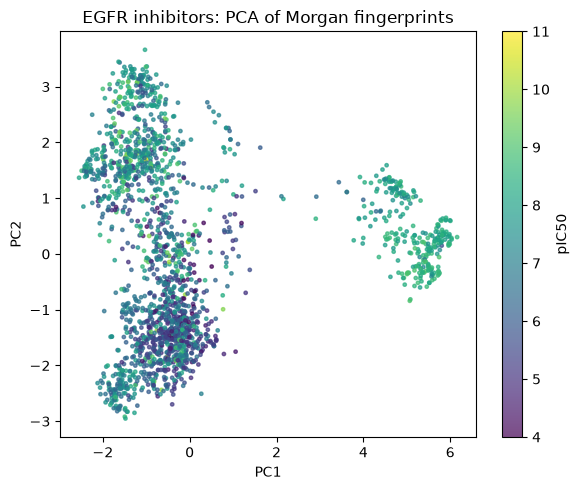

In [4]:
pca = PCA(n_components=50, random_state=0)
X_pca = pca.fit_transform(X)
print("variance explained by PC1, PC2:", pca.explained_variance_ratio_[:2].round(3))
print("cumulative variance, 50 PCs:   ", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=egfr["p_activity"], cmap="viridis", s=6, alpha=0.7)
plt.colorbar(sc, label="pIC50")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("EGFR inhibitors: PCA of Morgan fingerprints")
plt.tight_layout(); plt.show()

## 2. t-SNE: preserving local neighbourhoods

t-SNE places similar molecules close together. Distances *between* clusters and cluster sizes are
**not** meaningful, and the result depends on `perplexity` and the random seed. A common recipe is
to run it on the first 50 principal components.

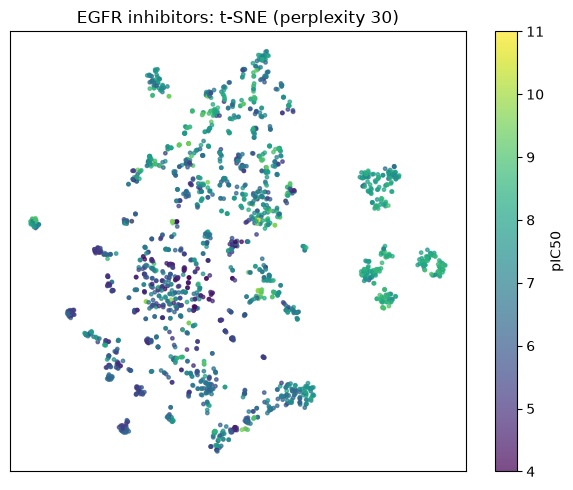

In [5]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0)
X_tsne = tsne.fit_transform(X_pca)

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=egfr["p_activity"], cmap="viridis", s=6, alpha=0.7)
plt.colorbar(sc, label="pIC50")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("EGFR inhibitors: t-SNE (perplexity 30)")
plt.tight_layout(); plt.show()

## 3. UMAP with a chemistry-aware metric

UMAP is faster than t-SNE on large sets and keeps somewhat more global structure. With binary
fingerprints we can use the **Jaccard** distance, which is 1 − Tanimoto.

/workspace/venvs/practical-cheminformatics-course/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


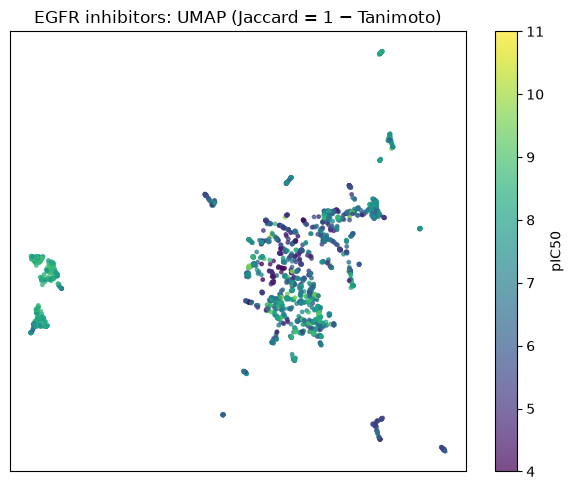

In [6]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # UMAP: harmless warnings about seeds/threads
import umap

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="jaccard", random_state=0)
X_umap = reducer.fit_transform(X.astype(bool))

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_umap[:, 0], X_umap[:, 1], c=egfr["p_activity"], cmap="viridis", s=6, alpha=0.7)
plt.colorbar(sc, label="pIC50")
ax.set_xticks([]); ax.set_yticks([]); ax.set_title("EGFR inhibitors: UMAP (Jaccard = 1 − Tanimoto)")
plt.tight_layout(); plt.show()

## 4. Which chemotypes form the islands?

Colour the UMAP by the 4-anilinoquinazoline substructure from Notebook 05.

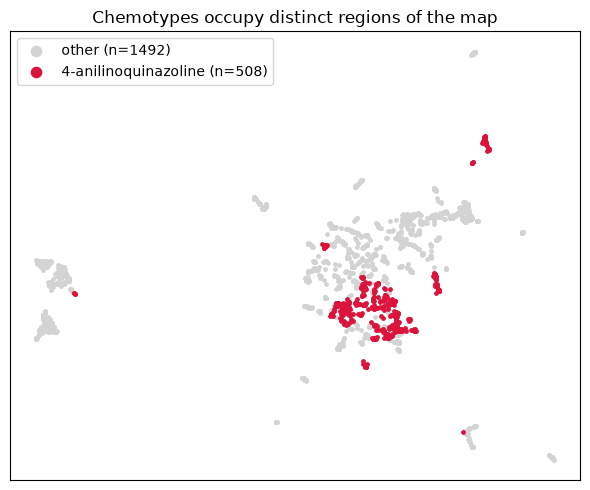

In [7]:
aq = Chem.MolFromSmarts("c1ccccc1[NX3;H1]c1ncnc2ccccc12")
egfr["anilinoquinazoline"] = [Chem.MolFromSmiles(s).HasSubstructMatch(aq) for s in egfr["smiles"]]

fig, ax = plt.subplots(figsize=(6, 5))
for flag, colour, label in [(False, "lightgrey", "other"), (True, "crimson", "4-anilinoquinazoline")]:
    m = egfr["anilinoquinazoline"] == flag
    ax.scatter(X_umap[m, 0], X_umap[m, 1], s=6, c=colour, label=f"{label} (n={m.sum()})")
ax.legend(markerscale=3); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Chemotypes occupy distinct regions of the map")
plt.tight_layout(); plt.show()

## 5. Comparing two datasets in descriptor space

Interpretable descriptors (instead of fingerprints) make the PCA axes easy to read.
Are the ESOL compounds and the EGFR inhibitors in the same region of chemical space?

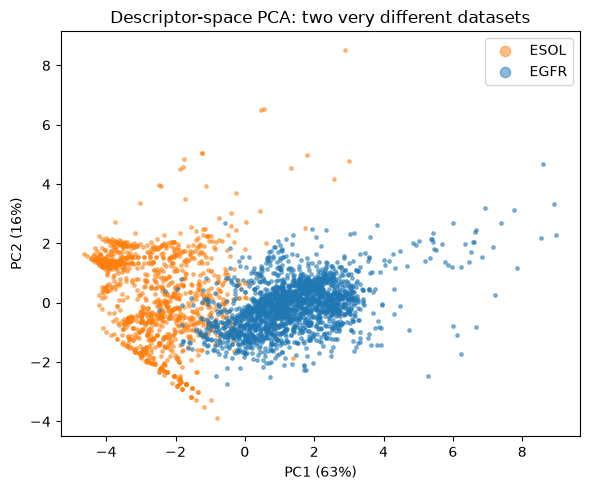

In [8]:
def props(smiles):
    rows = []
    for s in smiles:
        m = Chem.MolFromSmiles(s)
        rows.append([Descriptors.MolWt(m), Crippen.MolLogP(m), rdMolDescriptors.CalcTPSA(m),
                     rdMolDescriptors.CalcNumHBD(m), rdMolDescriptors.CalcNumHBA(m),
                     rdMolDescriptors.CalcNumRotatableBonds(m), rdMolDescriptors.CalcNumAromaticRings(m),
                     rdMolDescriptors.CalcFractionCSP3(m)])
    return pd.DataFrame(rows, columns=["MW", "logP", "TPSA", "HBD", "HBA", "RotB", "AroRings", "FracSP3"])

D = pd.concat([props(esol["smiles"]).assign(dataset="ESOL"),
               props(egfr["smiles"]).assign(dataset="EGFR")], ignore_index=True)
feats = D.columns[:-1]
Z = StandardScaler().fit_transform(D[feats])
pca_d = PCA(n_components=2).fit(Z)
P = pca_d.transform(Z)

fig, ax = plt.subplots(figsize=(6, 5))
for name, colour in [("ESOL", "tab:orange"), ("EGFR", "tab:blue")]:
    m = (D["dataset"] == name).values
    ax.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, c=colour, label=name)
ax.set_xlabel(f"PC1 ({pca_d.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca_d.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=3); ax.set_title("Descriptor-space PCA: two very different datasets")
plt.tight_layout(); plt.show()

In [9]:
pd.DataFrame(pca_d.components_.T, index=feats, columns=["PC1 loading", "PC2 loading"]).round(2)

,PC1 loading,PC2 loading
MW,0.43,0.01
logP,0.29,-0.41
TPSA,0.40,0.26
HBD,0.32,0.27
HBA,0.41,0.22
RotB,0.37,0.20
AroRings,0.38,-0.37
FracSP3,-0.15,0.69


The loadings tell you what each axis *means*. The two datasets barely overlap: a solubility model
trained on ESOL would be extrapolating on kinase inhibitors. Checking this overlap is the idea behind an
**applicability domain**.

### ✏️ Exercise 1

Re-run t-SNE with `perplexity=5` and `perplexity=100` and plot them side by side. What changes?

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, perp in zip(axes, [5, 100]):
    emb = TSNE(n_components=2, perplexity=perp, init="pca", random_state=0).fit_transform(X_pca)
    ax.scatter(emb[:, 0], emb[:, 1], c=egfr["p_activity"], cmap="viridis", s=5)
    ax.set_title(f"perplexity = {perp}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
# Low perplexity: many small, fragmented clusters. High perplexity: smoother, more global layout.
```

</details>

### ✏️ Exercise 2

How many principal components of the fingerprint matrix are needed to explain 50 % of the variance?

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
pca_full = PCA(random_state=0).fit(X)
n50 = int(np.searchsorted(np.cumsum(pca_full.explained_variance_ratio_), 0.5) + 1)
print(n50, "components explain 50% of the variance")
```

</details>

### ✏️ Exercise 3

Colour the UMAP map by the binary `active` label (pIC50 ≥ 7) instead of pIC50.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
fig, ax = plt.subplots(figsize=(6, 5))
for flag, colour in [(0, "lightgrey"), (1, "darkgreen")]:
    m = (egfr["active"] == flag).values
    ax.scatter(X_umap[m, 0], X_umap[m, 1], s=6, c=colour, label=f"active={flag} (n={m.sum()})")
ax.legend(markerscale=3); ax.set_xticks([]); ax.set_yticks([]); plt.show()
```

</details>

## Key takeaways

- PCA is linear, reproducible, and interpretable; t-SNE and UMAP reveal local neighbourhoods.
- In t-SNE/UMAP plots, distances between clusters and cluster sizes are not quantitative.
- Use maps to compare datasets and spot gaps, not as evidence on their own.

**Next:** [09 · Clustering and scaffolds](09_clustering_scaffolds.ipynb).